# **Домашнее задание №1 (base)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;

**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–4 (EDA, модели, категориальные признаки, бизнес-метрика) — 5 баллов;
- Часть 5, оформление репозитория — 2 балла;
- Часть 6, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

/var/folders/kg/17k9r8h12dg9ng84rzm5z4j80000gn/T/ipykernel_1797/1014525522.py:7: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

**Ответ.** Сиды фиксируют состояние генераторов случайных чисел (`random`, `numpy`, а также инициализацию моделей и разбиения выборок), чтобы при повторном запуске получались те же самые выборки, разбиения и результаты. Это делает эксперимент воспроизводимым и позволяет корректно сравнивать модели: разница в метриках тогда объясняется изменением модели/признаков, а не случайностью. Полная воспроизводимость не гарантирована при смене версий библиотек, оборудования и настроек параллелизма.

# **Часть 1 | EDA и визуализация**

Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.5 балла)
- Визуализации признаков и их анализ (1 балл)

Всего за эту часть можно набрать 2.5 балла.

## **Простейший EDA и обработка признаков (1.5 балла)**

In [2]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.45 балла)**

Вы уже встречались с pandas в первой половине семестра. Теперь будем постоянно (кроме некоторых случаев) использовать его для анализа данных и наслаивать навыки. Выполните операции, направленные на практику основных действий с `pandas`:

**0.1 балла**
- [ ] Отобразите 30 случайных строк тренировочного датасета.
- [ ] Отобразите первые 5 и последние 5 объектов тестового датасета
- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения
- [ ] Посмотрите, есть ли в данных явные дубликаты


**0.2 балла**
Ответьте на вопросы:
- [ ] О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?
- [ ] Достаточно ли метода duplicated для анализа дубликатов? Почему?

**0.15 балла**
- [ ] Постройте дашборд, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling)

In [3]:
print("30 случайных строк тренировочного датасета.")
display(df_train.sample(30, random_state=42))

30 случайных строк тренировочного датасета.


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
6565,Renault KWID Climber 1.0 MT BSIV,2019,300000,35000,Petrol,Individual,Manual,First Owner,23.01 kmpl,999 CC,67 bhp,91Nm@ 4250rpm,5.0
2943,Maruti Wagon R LXI,2013,225000,58343,Petrol,Trustmark Dealer,Manual,First Owner,21.79 kmpl,998 CC,67.05 bhp,90Nm@ 3500rpm,5.0
2024,Hyundai i20 Asta 1.2,2013,360000,30000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
263,Hyundai i20 1.2 Asta,2010,300000,70000,Petrol,Individual,Manual,First Owner,17.0 kmpl,1197 CC,80 bhp,"11.4 kgm at 4,000 rpm",5.0
4586,Skoda Octavia L and K 1.9 TDI MT,2005,250000,120000,Diesel,Individual,Manual,Third Owner,16.4 kmpl,1896 CC,90 bhp,"21.4@ 1,900(kgm@ rpm)",5.0
4479,Maruti Ciaz ZXi,2016,700000,20000,Petrol,Individual,Manual,First Owner,20.73 kmpl,1373 CC,91.1 bhp,130Nm@ 4000rpm,5.0
4881,Hyundai Grand i10 1.2 Kappa Magna BSIV,2017,445000,27000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
3583,Ford Ecosport 1.5 DV5 MT Trend,2016,515000,68609,Diesel,Dealer,Manual,First Owner,22.7 kmpl,1498 CC,89.84 bhp,204Nm@ 2000-2750rpm,5.0
6361,Hyundai Verna 1.4 VTVT,2014,500000,33400,Petrol,Individual,Manual,First Owner,17.43 kmpl,1396 CC,105.5 bhp,135.3Nm@ 5000rpm,5.0
4108,Hyundai i20 Era 1.2,2015,490000,45900,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0


In [4]:
print("первые 5 и последние 5 объектов тестового датасета")
display(df_test.head(), df_test.tail())

первые 5 и последние 5 объектов тестового датасета


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Mahindra Xylo E4 BS IV,2010,229999,168000,Diesel,Individual,Manual,First Owner,14.0 kmpl,2498 CC,112 bhp,260 Nm at 1800-2200 rpm,7.0
1,Tata Nexon 1.5 Revotorq XE,2017,665000,25000,Diesel,Individual,Manual,First Owner,21.5 kmpl,1497 CC,108.5 bhp,260Nm@ 1500-2750rpm,5.0
2,Honda Civic 1.8 S AT,2007,175000,218463,Petrol,Individual,Automatic,First Owner,12.9 kmpl,1799 CC,130 bhp,172Nm@ 4300rpm,5.0
3,Honda City i DTEC VX,2015,635000,173000,Diesel,Individual,Manual,First Owner,25.1 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0
4,Tata Indica Vista Aura 1.2 Safire BSIV,2011,130000,70000,Petrol,Individual,Manual,Second Owner,16.5 kmpl,1172 CC,65 bhp,96 Nm at 3000 rpm,5.0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
995,Hyundai i10 Magna 1.1L,2008,250000,100000,Petrol,Individual,Manual,Second Owner,19.81 kmpl,1086 CC,68.05 bhp,99.04Nm@ 4500rpm,5.0
996,Hyundai i20 2015-2017 Sportz 1.2,2017,440000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
997,Hyundai i20 Era Diesel,2009,340000,40000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
998,Hyundai i10 Asta,2012,350000,25000,Petrol,Individual,Manual,First Owner,20.36 kmpl,1197 CC,78.9 bhp,111.8Nm@ 4000rpm,5.0
999,Honda City i DTec SV,2016,700000,110000,Diesel,Individual,Manual,First Owner,26.0 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0


In [5]:
missing_cols_train = df_train.columns[df_train.isna().any()].tolist()
missing_cols_test = df_test.columns[df_test.isna().any()].tolist()
print("Столбцы с пропусками (train):", missing_cols_train)
print("Столбцы с пропусками (test): ", missing_cols_test)
print("Количество пропусков (train):\n", df_train.isna().sum())
print("Явные дубликаты: train =", df_train.duplicated().sum(),
      ", test =", df_test.duplicated().sum())

Столбцы с пропусками (train): ['mileage', 'engine', 'max_power', 'torque', 'seats']
Столбцы с пропусками (test):  ['mileage', 'engine', 'max_power', 'torque', 'seats']
Количество пропусков (train):
 name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          202
engine           202
max_power        196
torque           203
seats            202
dtype: int64
Явные дубликаты: train = 985 , test = 62


In [6]:
import os
import tempfile

profile_path = os.path.join(tempfile.gettempdir(), "hw1_cars_profile.html")
profile = ProfileReport(df_train, title="Cars train — EDA", progress_bar=False)
profile.to_file(profile_path)
print("Дашборд ydata-profiling сохранён:", profile_path)


  0%|          | 0/13 [00:00<?, ?it/s]


  8%|▊         | 1/13 [00:00<00:01,  6.81it/s]


100%|██████████| 13/13 [00:00<00:00, 69.00it/s]

Дашборд ydata-profiling сохранён: /var/folders/kg/17k9r8h12dg9ng84rzm5z4j80000gn/T/hw1_cars_profile.html


**Краткая теория.** EDA отвечает на вопросы о структуре данных, типы, пропуски (`isna`), дубликаты (`duplicated`), описательные статистики. Медиана устойчива к выбросам и поэтому часто используется для заполнения пропусков.

**Ответы на вопросы.**
- По случайным/верхним/нижним строкам видно структуру таблицы, типы полей, примеры значений и отдельные явные аномалии. Нельзя судить о распределениях, доле пропусков, редких категориях, выбросах и связях признаков: несколько строк не репрезентируют всю выборку.
- `duplicated()` без аргументов находит только полные совпадения всех столбцов. Недостаточно: дубли могут отличаться целевой переменной или опечаткой; нужно проверять совпадение по подмножеству признаков (задание 2), а иногда и нечёткие совпадения.

Дашборд `ydata-profiling` построен по `df_train` и сохранён в HTML-файл во временной директории (путь выведен кодом).

### **Задание 2 (0.5 балла)**

На прошлом шаге вы рассмотрели дубликаты. Однако дубликат может быть связан не только с полным повторением информации в нескольких строках, но и частичным. Например, объект мог быть внесён в базу данных с разным значением целевой переменной. В этом шаге займемся такими дублями!

**Ваши действия:**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.1 балла)
- [ ] Отобразите такие объекты (0.15 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.15 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.1 балла)


In [7]:
feature_cols = [c for c in df_train.columns if c != "selling_price"]
dup_mask = df_train.duplicated(subset=feature_cols, keep=False)

print("Строк с неуникальным признаковым описанием:", dup_mask.sum())
print("Лишних строк (дублей, кроме первой):", df_train.duplicated(subset=feature_cols).sum())
display(df_train[dup_mask].sort_values(feature_cols).head(5))

df_train = (df_train.drop_duplicates(subset=feature_cols, keep="first")
            .reset_index(drop=True))

df_train

Строк с неуникальным признаковым описанием: 1799
Лишних строк (дублей, кроме первой): 1159


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1703,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
6307,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
1836,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
6704,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
117,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
3,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
4,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5835,Hyundai Santro Xing GLS,2008,120000,191000,Petrol,Individual,Manual,First Owner,17.92 kmpl,1086 CC,62.1 bhp,96.1Nm@ 3000rpm,5.0
5836,Maruti Wagon R VXI BS IV with ABS,2013,260000,50000,Petrol,Individual,Manual,Second Owner,18.9 kmpl,998 CC,67.1 bhp,90Nm@ 3500rpm,5.0
5837,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
5838,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0


**Ответ.** Одинаковое признаковое описание имеет 1799 строк (включая первые в каждой группе), то есть 1159 лишних копий. После удаления с `keep="first"` и сброса индекса получилось 5840 строк. Полностью совпадающих строк было 985: разница в 174 строки — это как раз объекты с одинаковыми признаками, но разной ценой; для них оставлена первая по порядку запись.

In [8]:
assert df_train.shape == (5840, 13)

Отлично! Мы избавились от маленьких и явных проблем. Теперь перейдем к более сложным недостаткам полученной таблицы.

### **Задание 3 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Удалите столбец ``torque``


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.
- Столбец ``torque`` мы удаляем для простоты. В идеальном случае, его также стоило бы предобработать.

In [9]:
for data in (df_train, df_test):
    for col in ["mileage", "engine", "max_power"]:
        data[col] = pd.to_numeric(data[col].astype(str).str.split().str[0],
                                  errors="coerce")
    data.drop(columns=["torque"], inplace=True)

print(df_train[["mileage", "engine", "max_power"]].dtypes)
print(df_test[["mileage", "engine", "max_power"]].dtypes)

mileage      float64
engine       float64
max_power    float64
dtype: object
mileage      float64
engine       float64
max_power    float64
dtype: object


**Краткая теория.** Признаки `mileage`, `engine`, `max_power` — числовые, но сохранены как строки с единицами измерения (`kmpl`, `km/kg`, `CC`, `bhp`). Разделение по пробелу и взятие первого токена даёт числовое значение. `torque` удаляем: строки вида `190Nm@ 2000rpm` и `22.4 kgm at ...` требуют отдельного парсинга и двух разных единиц. Примечание: при `km/kg` нельзя просто приравнять значение к `kmpl` — в задании требуется только убрать единицы.

### **Задание 4 (0.15 балла)**

В Задании 1 мы обнаружили пропуски. Давайте избавимся от них.

**Шаг 1 (0.05 балла)**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось. Заполнение пропусков проводите для обоих наборов данных, если необходимо

**Важно!**

При заполнении пропусков и в тестовом, и тренировочном наборах данных вы определяетесь со стратегией предобработки пропущенных значений при потенциальной работе модели.

Так как в теоретическом случае вы не имеете доступа к тестовой выборке, то заполняемое значение (у нас — медиана) вы считаете по *тренировочному* набору данных и им же заполняете *тестовый*.

In [10]:
medians = df_train.median(numeric_only=True)
print("Медианы, посчитанные по train:\n", medians)

for data in (df_train, df_test):
    for col in data.columns[data.isna().any()]:
        data[col] = data[col].fillna(medians[col])

print("Осталось пропусков: train =", df_train.isna().sum().sum(),
      ", test =", df_test.isna().sum().sum())

Медианы, посчитанные по train:
 year               2014.00
selling_price    405000.00
km_driven         70000.00
mileage              19.37
engine             1248.00
max_power            81.86
seats                 5.00
dtype: float64
Осталось пропусков: train = 0 , test = 0


**Краткая теория.** Заполнение пропуска медианой — простой устойчивый способ. Медианы считаются **только по train** и применяются к train и test: использование статистик test было бы утечкой данных (data leakage), а в реальной работе тестовые данные на этапе обучения недоступны.

**Шаг 2 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.

In [11]:
for data in (df_train, df_test):
    data["engine"] = data["engine"].astype(int)
    data["seats"] = data["seats"].astype(int)

print(df_train.dtypes)

name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage          float64
engine             int64
max_power        float64
seats              int64
dtype: object


### **Задание 5 (0.15 балла)**

Отлично! Мы провели "косметическую" предобработку и теперь готовы сделать важный шаг в контексте анализа данных. А именно — посмотреть на статистики!

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сделайте вывод.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

**Примечание:**

Более корректно рассматривать статистики до заполнения пропусков и после, чтобы убедиться, что мы не внесли каких-либо серьезных сдвигов в изначальные распределения.

In [12]:
print("ЧИСЛОВЫЕ ПРИЗНАКИ — TRAIN")
display(df_train.describe())
print("ЧИСЛОВЫЕ ПРИЗНАКИ — TEST")
display(df_test.describe())

print("КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ — TRAIN")
display(df_train.describe(include="object"))
print("КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ — TEST")
display(df_test.describe(include="object"))

ЧИСЛОВЫЕ ПРИЗНАКИ — TRAIN


,year,selling_price,km_driven,mileage,engine,max_power,seats
count,5840.000000,5.840000e+03,5.840000e+03,5840.000000,5840.000000,5840.000000,5840.000000
mean,2013.428425,5.229601e+05,7.395224e+04,19.430841,1429.448973,87.906371,5.426712
std,4.095622,5.354320e+05,6.007114e+04,3.985973,485.662834,31.640418,0.982344
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,2.000000
25%,2011.000000,2.500000e+05,3.900000e+04,16.950000,1197.000000,68.000000,5.000000
50%,2014.000000,4.050000e+05,7.000000e+04,19.370000,1248.000000,81.860000,5.000000
75%,2017.000000,6.400000e+05,1.000000e+05,22.300000,1498.000000,99.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,14.000000


ЧИСЛОВЫЕ ПРИЗНАКИ — TEST


,year,selling_price,km_driven,mileage,engine,max_power,seats
count,1000.000000,1.000000e+03,1000.000000,1000.00000,1000.00000,1000.000000,1000.000000
mean,2013.681000,6.179010e+05,71393.341000,19.33881,1454.87600,90.841670,5.403000
std,4.012149,7.585539e+05,48486.218662,3.95175,521.99574,34.893389,0.912921
min,1995.000000,3.100000e+04,1303.000000,0.00000,624.00000,34.200000,4.000000
25%,2011.000000,2.500000e+05,37000.000000,16.55000,1197.00000,69.000000,5.000000
50%,2014.000000,4.349990e+05,61500.000000,19.37000,1248.00000,82.425000,5.000000
75%,2017.000000,6.700000e+05,100000.000000,22.30000,1582.00000,102.000000,5.000000
max,2020.000000,6.000000e+06,375000.000000,32.26000,3604.00000,280.000000,9.000000


КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ — TRAIN


,name,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840,5840
unique,1924,4,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,91,3177,5223,5336,3603


КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ — TEST


,name,fuel,seller_type,transmission,owner
count,1000,1000,1000,1000,1000
unique,621,4,3,2,5
top,Maruti Alto 800 LXI,Diesel,Individual,Manual,First Owner
freq,15,534,837,877,623


**Вывод.** Медианные значения и квантили числовых признаков на train и test близки (годы ~2014, пробег ~70 тыс., engine 1248, seats 5), доли категорий (`fuel`, `seller_type`, `transmission`, `owner`) также сопоставимы. Заполнение медианами почти не сдвинуло распределения (пропусков было ~3%). Разброс цен большой, распределение цены правостороннее — это видно и в задании 8.

In [13]:
# torque удалён в Задании 3, поэтому столбцов 12
assert df_train.shape == (5840, 12)

## **Визуализации (1 балл)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

**Краткая теория.** `pairplot` показывает гистограмки каждого признака на диагонали и облака рассеяния для каждой пары. По ним можно выдвинуть гипотезы о виде связи (линейная/нелинейная), выбросах и о том, похожи ли распределения train и test. Это только гипотезы: количество точек и перекрытие классов не заменяют числовую оценку корреляции.

### **Задание 6 (0.4 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

Числовые признаки: ['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']


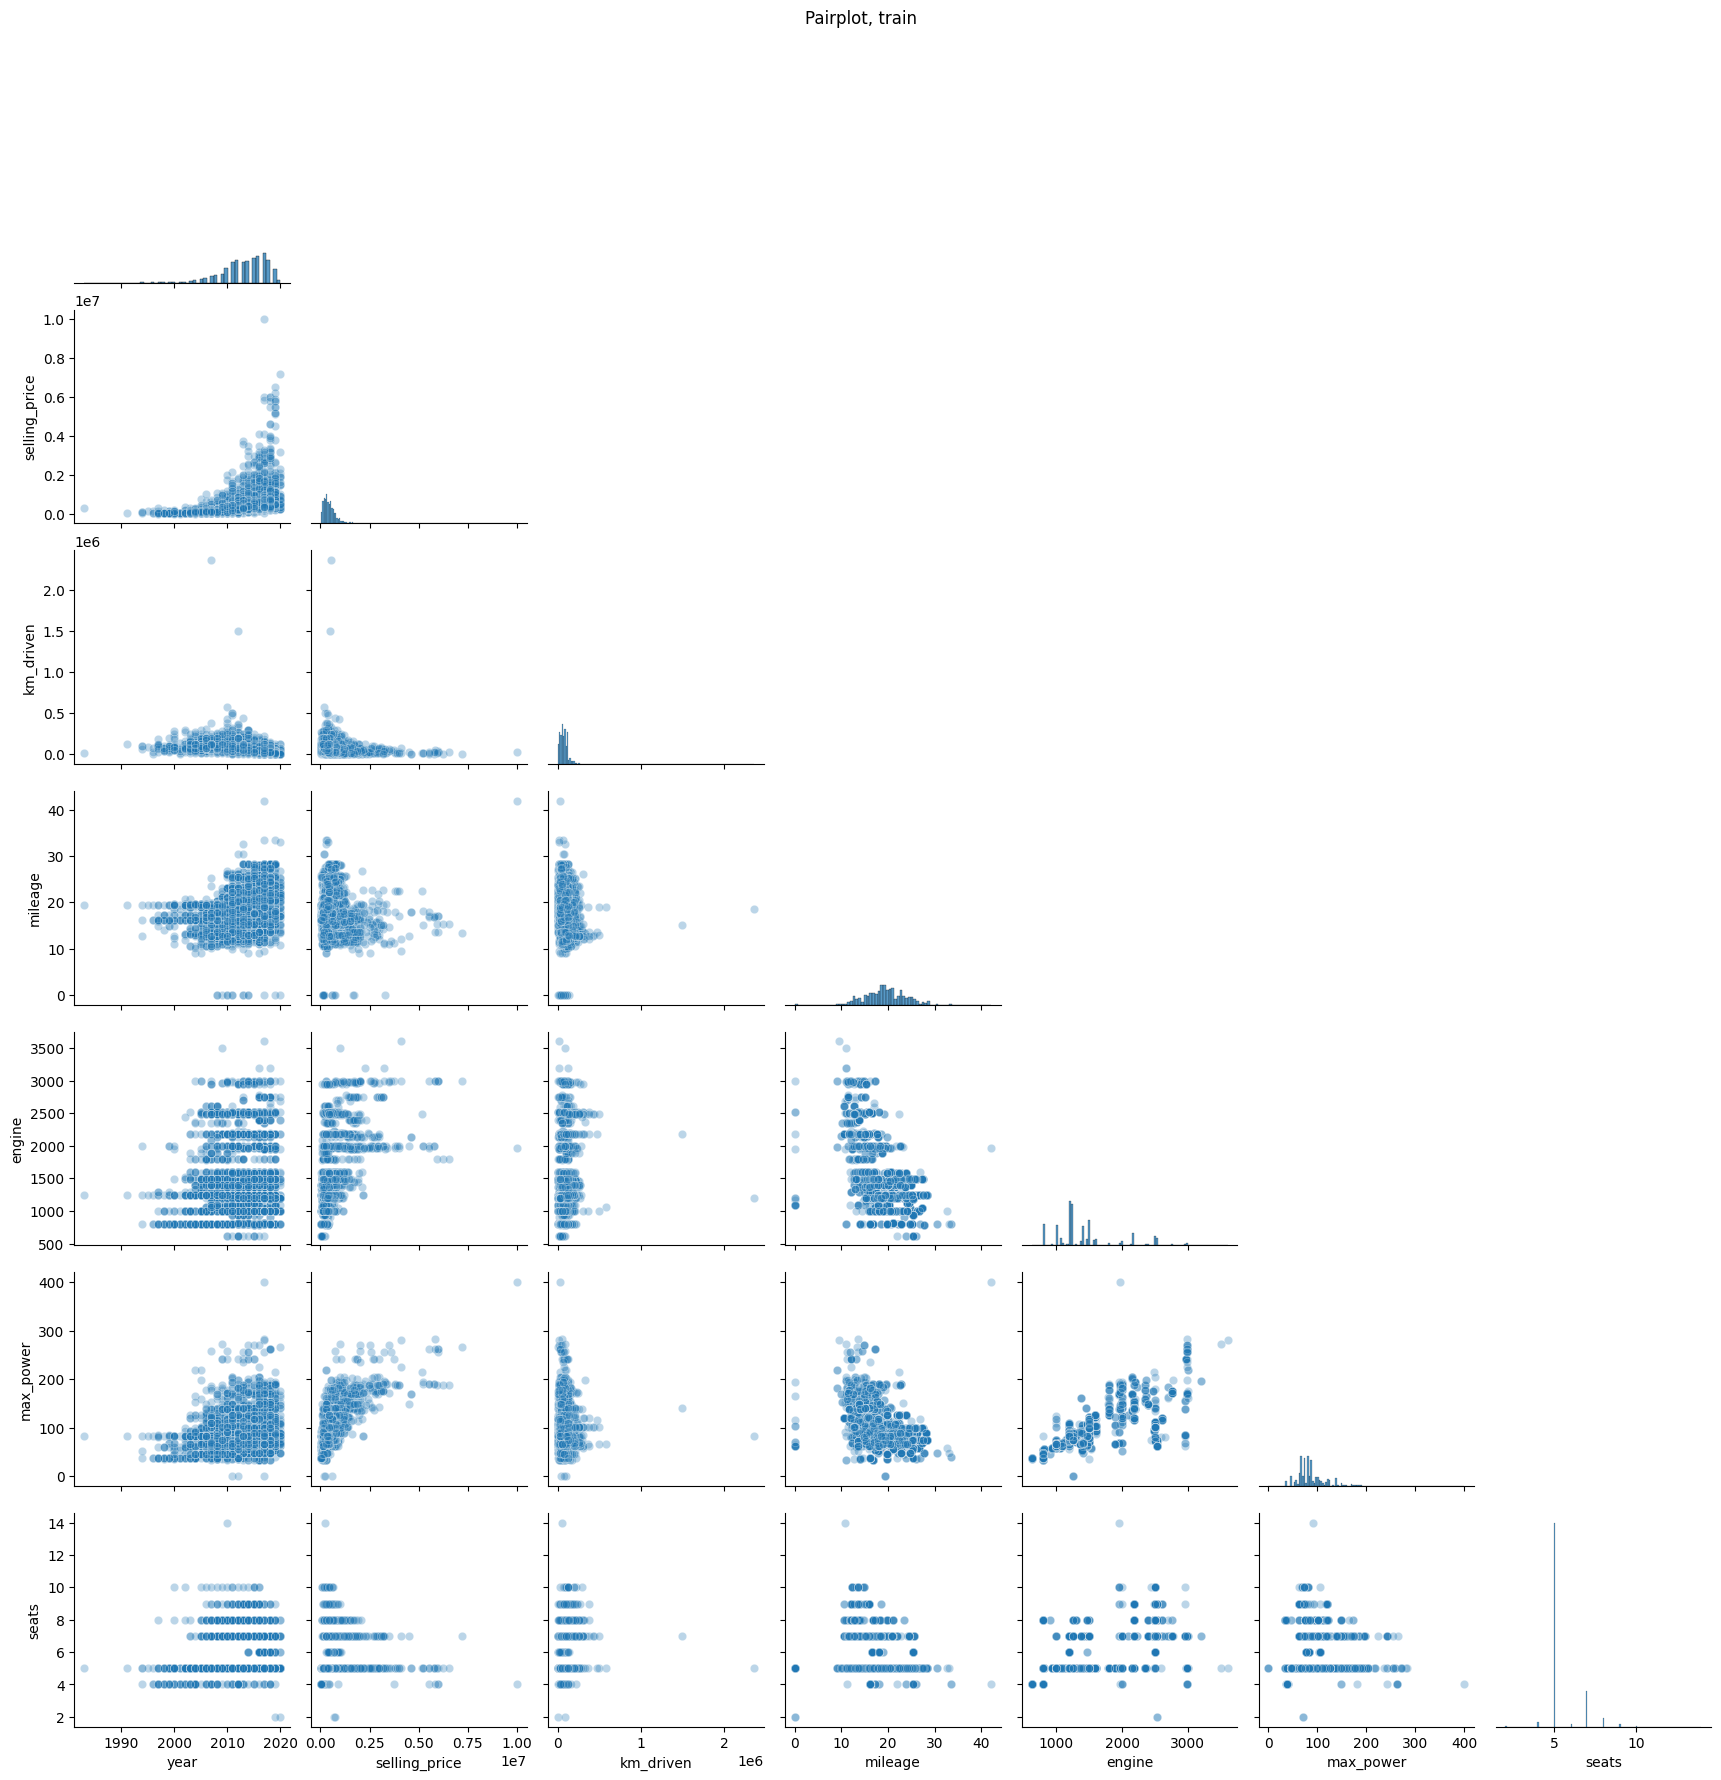

In [14]:
num_cols = df_train.select_dtypes(include=np.number).columns.tolist()
print("Числовые признаки:", num_cols)
sns.pairplot(df_train[num_cols], diag_kind="hist", corner=True, plot_kws={"alpha": 0.3})
plt.suptitle("Pairplot, train", y=1.02)
plt.show()

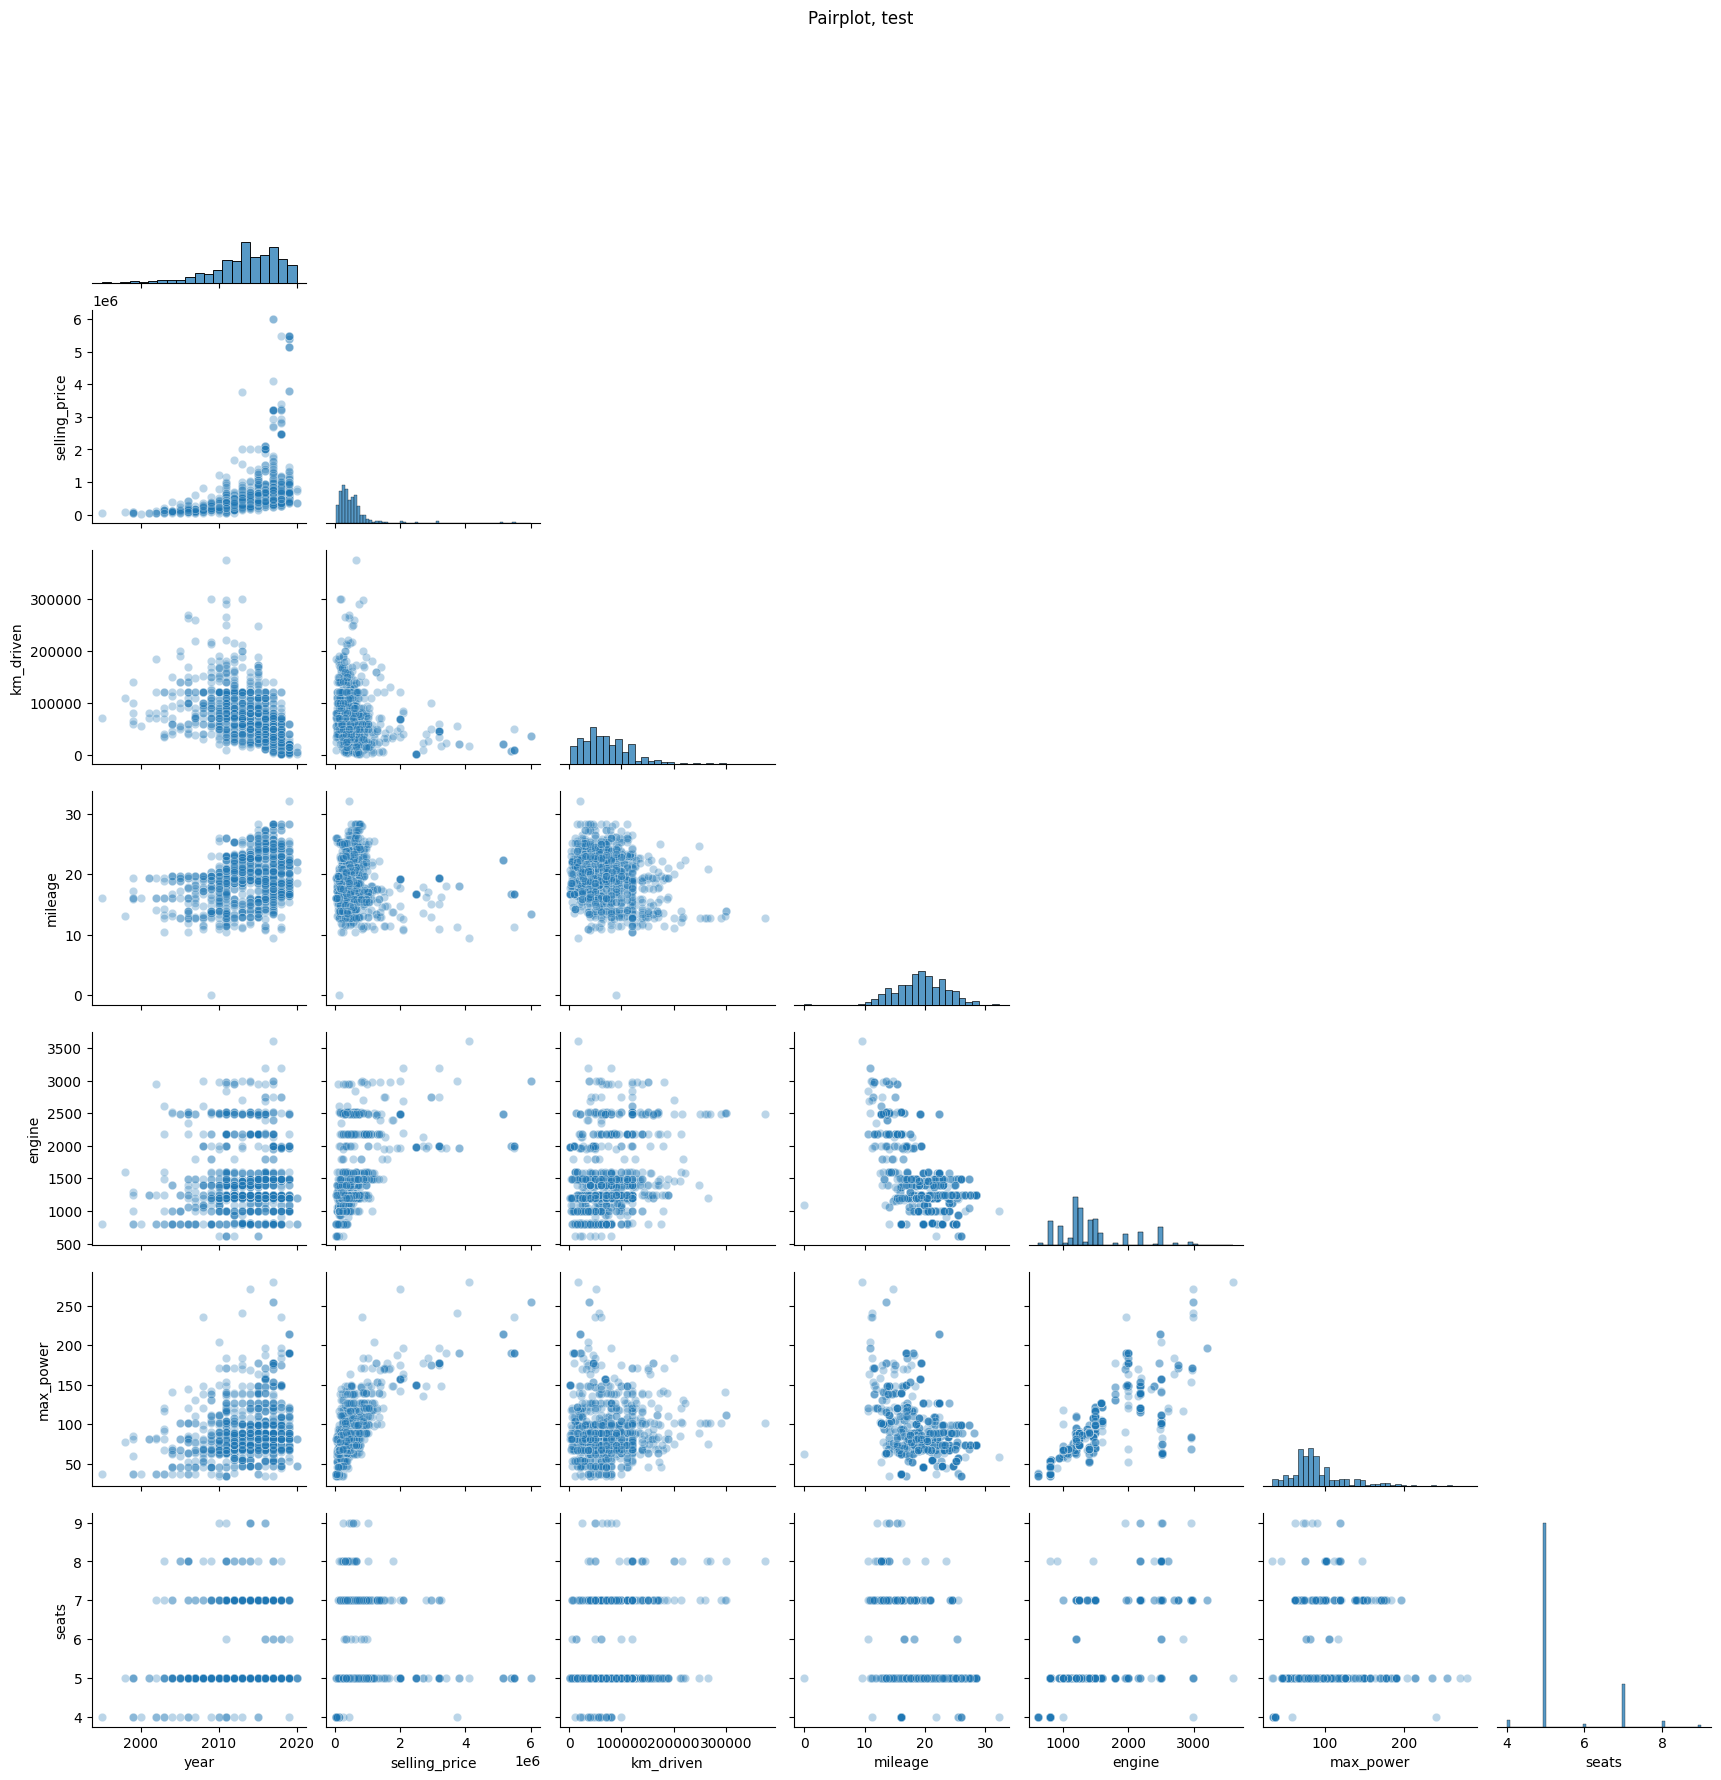

In [15]:
sns.pairplot(df_test[num_cols], diag_kind="hist", corner=True, plot_kws={"alpha": 0.3})
plt.suptitle("Pairplot, test", y=1.02)
plt.show()

**Ответы на вопросы (pairplot).**
- С ценой сильнее всего связаны `max_power` и `engine` (облако вытянуто вверх), заметна положительная связь с `year` и отрицательная с `km_driven` и `mileage`. Связи не строго линейные, у цены много выбросов вправо.
- Признаки `engine`, `max_power`, `seats` связаны между собой положительно; `mileage` отрицательно связана с `engine` и `seats`; `year` отрицательно связан с `km_driven`.
- Совокупности на train и test похожи: формы облаков и гистограмм фактически совпадают, и разбиение данных на трейн/тест можно считать корректным. Перемешивать данные не нужно.

**Краткая теория.** Коэффициент корреляции Пирсона — нормированная ковариация: $r_{xy}=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i(x_i-\bar x)^2\sum_i(y_i-\bar y)^2}}$, принимает значения от −1 до +1 и измеряет только **линейную** связь. Он чувствителен к выбросам, а корреляция не означает причинно-следственной связи.

### **Задание 7 (0.35 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

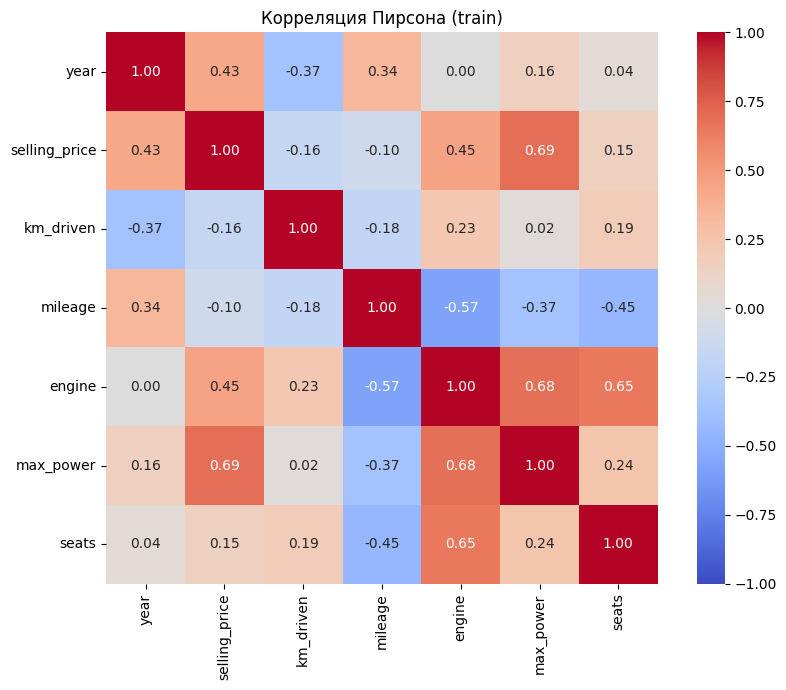

,year,selling_price,km_driven,mileage,engine,max_power,seats
year,1.000,0.427,-0.369,0.341,0.003,0.157,0.041
selling_price,0.427,1.000,-0.165,-0.105,0.448,0.693,0.150
km_driven,-0.369,-0.165,1.000,-0.182,0.230,0.025,0.192
mileage,0.341,-0.105,-0.182,1.000,-0.573,-0.373,-0.451
engine,0.003,0.448,0.230,-0.573,1.000,0.681,0.652
max_power,0.157,0.693,0.025,-0.373,0.681,1.000,0.244
seats,0.041,0.150,0.192,-0.451,0.652,0.244,1.000


In [16]:
corr = df_train[num_cols].corr(method="pearson")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Корреляция Пирсона (train)")
plt.tight_layout()
plt.show()
display(corr.round(3))

- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?

**Ответы на вопросы (корреляции).**
- Наименее скоррелированы `year` и `engine`: r ≈ 0.003 (практически ноль). Следом идут `km_driven` и `max_power` (r ≈ 0.025).
- Довольно сильная положительная линейная зависимость: `selling_price` и `max_power` (r ≈ 0.693), а также `engine` и `max_power` (r ≈ 0.681), `engine` и `seats` (r ≈ 0.652).
- Утверждение верно лишь как статистическая тенденция: correlate(year, km_driven) ≈ −0.369. Чем меньше год выпуска (старее машина), тем больше в среднем пробег. Но связь умеренная, и причина не в «малом годе» как таковом, а в возрасте автомобиля; корреляция не доказывает причину.

### **Задание 8 (0.25 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

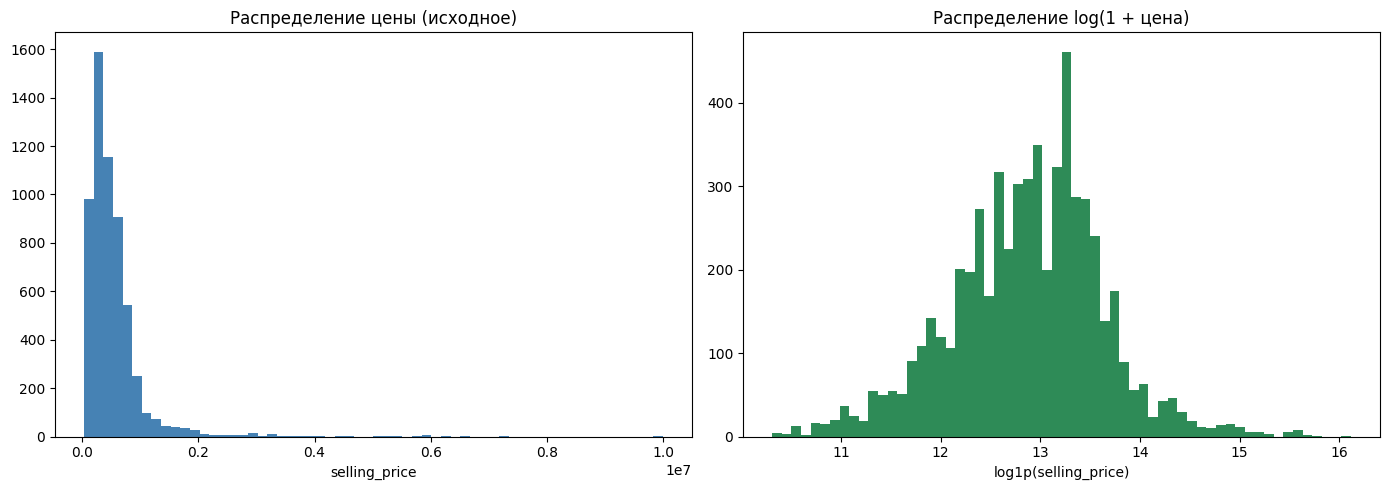

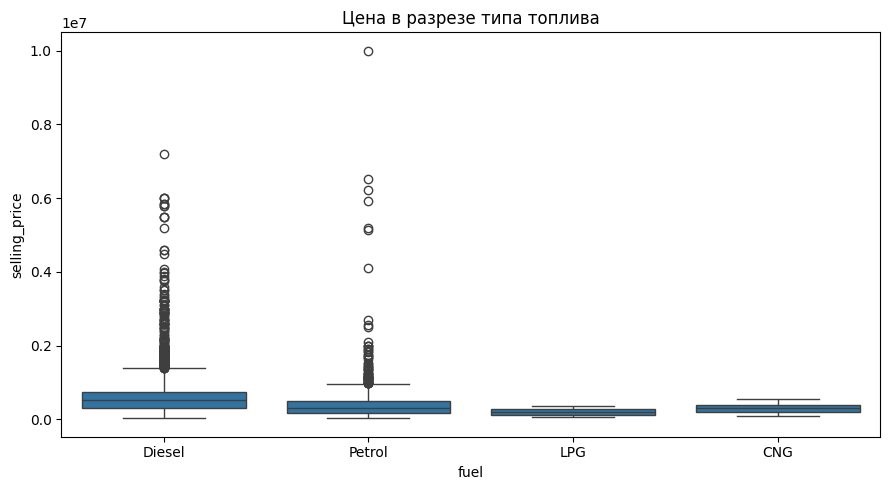

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_train["selling_price"], bins=60, color="steelblue")
axes[0].set_title("Распределение цены (исходное)")
axes[0].set_xlabel("selling_price")
axes[1].hist(np.log1p(df_train["selling_price"]), bins=60, color="seagreen")
axes[1].set_title("Распределение log(1 + цена)")
axes[1].set_xlabel("log1p(selling_price)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_train, x="fuel", y="selling_price")
plt.title("Цена в разрезе типа топлива")
plt.tight_layout()
plt.show()

**Почему это важно.** Гистограммы показывают сильную правостороннюю асимметрию цены: `log1p` делает распределение почти симметричным, поэтому для цены можно было бы использовать логарифмическую целевую переменную. Ящик с усами по `fuel` показывает, что тип топлива влияет на цену (дизельные авто в среднем дороже), а разброс внутри групп велик — значит, одних вещественных признаков недостаточно и категориальные фичи стоит добавить.

# **Часть 2 | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.25 балла.

**Краткая теория (часть 2).** Линейная регрессия ищет $\hat y = X\beta$, минимизируя $SSE=\sum_i(y_i-\hat y_i)^2$ (МНК). $R^2=1-SSE/SST$ — доля объяснённой дисперсии; $MSE=SSE/n$ — средняя квадратичная ошибка в тех же единицах, что и $y$ в квадрате. Стандартизация ($z=(x-\mu)/\sigma$) нужна, чтобы сравнивать коэффициенты по модулю и чтобы регуляризация не зависела от масштабов признаков. L1 (`Lasso`) минимизирует $SSE+\alpha\sum|\beta_j|$ и может обнулять коэффициенты; L2 (`Ridge`) минимизирует $SSE+\alpha\sum\beta_j^2$ и только сжимает их. Гиперпараметр $\alpha$ подбирается кросс-валидацией: данные делятся на K фолдов, модель обучается на K−1 и оценивается на оставшемся.

### **Задание 9 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test при разбиении. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [18]:
y_train = df_train["selling_price"].copy()
cat_cols_all = ["name", "fuel", "seller_type", "transmission", "owner"]
X_train = df_train.drop(columns=["selling_price"] + cat_cols_all).copy()
print("Признаки модели:", X_train.columns.tolist())

Признаки модели: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']


In [19]:
print("Вещественные признаки: year, km_driven, mileage, engine, max_power, seats")
print("Целевая переменная: selling_price (в рупиях)")
print("Категориальные столбцы исключены, так как LinearRegression работает только с числами.")

Вещественные признаки: year, km_driven, mileage, engine, max_power, seats
Целевая переменная: selling_price (в рупиях)
Категориальные столбцы исключены, так как LinearRegression работает только с числами.


In [20]:
y_test = df_test["selling_price"].copy()
X_test = df_test.drop(columns=["selling_price"] + cat_cols_all).copy()
print("Формы:", X_train.shape, X_test.shape)

Формы: (5840, 6) (1000, 6)


### **Задание 10 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [21]:
results = {}

def evaluate(name, model, X_tr, X_te):
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    metrics = {
        "R2_train": r2_score(y_train, pred_tr),
        "MSE_train": MSE(y_train, pred_tr),
        "R2_test": r2_score(y_test, pred_te),
        "MSE_test": MSE(y_test, pred_te),
    }
    results[name] = metrics
    print(f"{name}: R2_train={metrics['R2_train']:.4f}  "
          f"MSE_train={metrics['MSE_train']:,.0f}  "
          f"R2_test={metrics['R2_test']:.4f}  "
          f"MSE_test={metrics['MSE_test']:,.0f}")
    return metrics


linear_model = LinearRegression().fit(X_train, y_train)
evaluate("LinearRegression", linear_model, X_train, X_test)

LinearRegression: R2_train=0.5923  MSE_train=116,874,153,930  R2_test=0.5941  MSE_test=233,298,779,730


{'R2_train': 0.5922591702157294,
 'MSE_train': 116874153930.02917,
 'R2_test': 0.5941419794788381,
 'MSE_test': 233298779730.45758}

**Вывод (задание 10).** Линейная регрессия на шести вещественных признаках даёт $R^2_{train} \approx 0.5923$, $R^2_{test} \approx 0.5941$, $MSE_{test}\approx 2.33\cdot10^{11}$. Качество на тесте не хуже, чем на трейне — переобучения нет, но модель объясняет только ~59% дисперсии цены. Большая MSE отчасти объясняется выбросами в цене (квадратичная ошибка сильно на них реагирует).

### **Задание 11 (0.15 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [22]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

linear_scaled = LinearRegression().fit(X_train_scaled, y_train)
evaluate("LinearRegression (scaled)", linear_scaled, X_train_scaled, X_test_scaled)

LinearRegression (scaled): R2_train=0.5923  MSE_train=116,874,153,930  R2_test=0.5941  MSE_test=233,298,779,730


{'R2_train': 0.5922591702157303,
 'MSE_train': 116874153930.02892,
 'R2_test': 0.5941419794788521,
 'MSE_test': 233298779730.44962}

### **Задание 12 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

In [23]:
importance = (pd.Series(linear_model.coef_, index=X_train.columns)
              .sort_values(key=abs, ascending=False))
display(importance.round(1))

year         37304.6
seats       -23628.3
max_power    10203.2
mileage       7234.5
engine         126.0
km_driven       -0.7
dtype: float64

In [24]:
importance = (pd.Series(linear_scaled.coef_, index=X_train.columns)
              .sort_values(key=abs, ascending=False))
display(importance.round(1))

max_power    322807.4
year         152772.6
engine        61178.5
km_driven    -44158.8
mileage       28833.9
seats        -23209.1
dtype: float64

**Ответ (задание 12).** После стандартизации коэффициенты сопоставимы. Наиболее информативный признак — `max_power` (коэффициент ≈ +3.23e5): при росте мощности на одно стандартное отклонение предсказанная цена растёт примерно на 323 тыс. Далее идут `year` и `engine`. `seats` имеет отрицательный коэффициент, что скорее всего отражает корреляции с типом кузова, а не реальный отрицательный эффект.

### **Задание 13 (0.25 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [25]:
lasso_default = Lasso().fit(X_train_scaled, y_train)
evaluate("Lasso (default)", lasso_default, X_train_scaled, X_test_scaled)

Lasso (default): R2_train=0.5923  MSE_train=116,874,153,940  R2_test=0.5941  MSE_test=233,299,450,599


{'R2_train': 0.5922591701804456,
 'MSE_train': 116874153940.1429,
 'R2_test': 0.5941408124026637,
 'MSE_test': 233299450599.16928}

In [26]:
lasso_coefs = pd.Series(lasso_default.coef_, index=X_train.columns)
display(lasso_coefs.round(2))
print("Обнулилось весов:", int((lasso_coefs == 0).sum()), "из", len(lasso_coefs))
print("alpha по умолчанию =", lasso_default.alpha)

year         152772.39
km_driven    -44157.69
mileage       28832.04
engine        61173.66
max_power    322808.24
seats        -23206.26
dtype: float64

Обнулилось весов: 0 из 6
alpha по умолчанию = 1.0


**Ответ (задание 13).** Lasso с $\alpha=1$ даёт те же метрики, что и МНК, и **не обнуляет ни одного веса**. Причина: штраф $\alpha\sum|\beta_j|$ слишком мал по сравнению с невязкой, потому что целевая переменная измерена в сотнях тысяч/миллионах, а признаки стандартизованы. Чтобы Lasso начал отбирать признаки, нужно увеличить $\alpha$ на несколько порядков (см. задание 14).

### **Задание 14 Финальный рывок (0.5 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [27]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    lasso_search = GridSearchCV(
        Lasso(max_iter=200000),
        {"alpha": np.logspace(-3, 5, 41)},
        cv=10, scoring="r2", n_jobs=-1,
    ).fit(X_train_scaled, y_train)

best_lasso = lasso_search.best_estimator_
print("Лучший alpha:", best_lasso.alpha)
print("CV R2:", round(lasso_search.best_score_, 4))
print("Всего комбинаций:", len(lasso_search.cv_results_["params"]),
      "=> обучено моделей:", len(lasso_search.cv_results_["params"]) * 10,
      "+ 1 на refit")
evaluate("Lasso (grid)", best_lasso, X_train_scaled, X_test_scaled)

Лучший alpha: 25118.864315095823
CV R2: 0.575
Всего комбинаций: 41 => обучено моделей: 410 + 1 на refit
Lasso (grid): R2_train=0.5832  MSE_train=119,470,402,776  R2_test=0.5661  MSE_test=249,404,411,759


{'R2_train': 0.5832015931274972,
 'MSE_train': 119470402776.14854,
 'R2_test': 0.5661238306400148,
 'MSE_test': 249404411759.1414}

In [28]:
lasso_best_coefs = pd.Series(best_lasso.coef_, index=X_train.columns)
display(lasso_best_coefs.round(1))
print("Признаки с нулевыми весами:", lasso_best_coefs[lasso_best_coefs == 0].index.tolist())

year         146685.3
km_driven    -16953.2
mileage           0.0
engine            0.0
max_power    323212.2
seats            -0.0
dtype: float64

Признаки с нулевыми весами: ['mileage', 'engine', 'seats']


**Ответы (задание 14, Lasso).** Сетка из 41 значения `alpha` × 10 фолдов = **410 обученных моделей** (плюс 1 повторная модель на refit). Лучший $\alpha \approx 2.5\cdot10^4$ (CV $R^2\approx0.575$). При такой регуляризации обнулились 3 веса: `mileage`, `engine` и `seats` — Lasso действительно выполнил отбор признаков, оставив в основном `max_power` и `year`. На тесте $R^2$ немного ниже, чем у МНК (0.566 против 0.594): сильная регуляризация снижает дисперсию, но добавляет смещение.

**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [29]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    en_search = GridSearchCV(
        ElasticNet(max_iter=200000),
        {"alpha": np.logspace(-3, 5, 17), "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]},
        cv=10, scoring="r2", n_jobs=-1,
    ).fit(X_train_scaled, y_train)

best_en = en_search.best_estimator_
print("Лучшие параметры:", en_search.best_params_)
print("CV R2:", round(en_search.best_score_, 4))
print("Всего комбинаций:", len(en_search.cv_results_["params"]),
      "=> обучено моделей:", len(en_search.cv_results_["params"]) * 10,
      "+ 1 на refit")
evaluate("ElasticNet (grid)", best_en, X_train_scaled, X_test_scaled)

Лучшие параметры: {'alpha': np.float64(0.31622776601683794), 'l1_ratio': 0.5}
CV R2: 0.5767
Всего комбинаций: 102 => обучено моделей: 1020 + 1 на refit
ElasticNet (grid): R2_train=0.5838  MSE_train=119,289,811,470  R2_test=0.5598  MSE_test=253,036,308,386


{'R2_train': 0.5838316250585416,
 'MSE_train': 119289811470.32158,
 'R2_test': 0.5598056048116449,
 'MSE_test': 253036308386.26077}

**Ответы (задание 14, ElasticNet).** Сетка: 17 значений `alpha` × 6 значений `l1_ratio` = 102 комбинации × 10 фолдов = **1020 обученных моделей** (плюс refit). Лучшие параметры: `alpha ≈ 0.316`, `l1_ratio = 0.5`, CV $R^2 \approx 0.577$. По $R^2$ на тесте (~0.560) ElasticNet не превзошёл обычную регрессию, но дал больше попаданий в 10%-ный коридор цены, чем МНК.

# **Часть 3 | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.75 балла.

**Краткая теория (часть 3).** One-hot кодирование заменяет категорию $k$ бинарным вектором. Параметр `drop_first=True` удаляет один столбец, чтобы избежать «ловушки дамми-переменных»: без этого сумма дамми равна 1 и они линейно зависимы со свободным членом (мультиколлинеарность), что делает коэффициенты неоднозначными. Если в test встречается категория, отсутствующая в train, после кодирования нужно выровнять столбцы по train и заполнить недостающие нулями — иначе размерности не совпадут.

**Задание 15 (0.1 балла)** Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

В этом домашнем задании мы предлагаем удалить его.

**Ваша задача:**
- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Удалите из них столбец `name`

In [30]:
X_train_cat = df_train.drop(columns=["selling_price", "name"]).copy()
X_test_cat = df_test.drop(columns=["selling_price", "name"]).copy()
print("Формы:", X_train_cat.shape, X_test_cat.shape)

Формы: (5840, 10) (1000, 10)


В другом случае, конечно, мы могли бы предобработать данный столбец (например, выделить из названия марку автомобиля). В этом задании этого делать не нужно.

In [31]:
assert X_train_cat.shape == (5840, 10)

In [32]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3177,5223,5336,3603


### **Задание 16 (0.4 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования. Обратите внимание, что во избежание мультиколлинеарности следует избавиться от одного из полученных столбцов при кодировании каждого признака методом OneHot.

In [33]:
ohe_cols = X_train_cat.select_dtypes(include="object").columns.tolist() + ["seats"]
print("Кодируемые столбцы:", ohe_cols)

first_level = {col: sorted(X_train_cat[col].unique())[0] for col in ohe_cols}

X_train_ohe = pd.get_dummies(X_train_cat, columns=ohe_cols).astype(float)
X_test_ohe = (pd.get_dummies(X_test_cat, columns=ohe_cols).astype(float)
              .reindex(columns=X_train_ohe.columns, fill_value=0))

drop_cols = [f"{col}_{level}" for col, level in first_level.items()]
X_train_ohe = X_train_ohe.drop(columns=drop_cols)
X_test_ohe = X_test_ohe.drop(columns=drop_cols)
print("После OHE:", X_train_ohe.shape, X_test_ohe.shape)

Кодируемые столбцы: ['fuel', 'seller_type', 'transmission', 'owner', 'seats']
После OHE: (5840, 23) (1000, 23)


**Важный нюанс.** Нельзя вызывать `get_dummies(drop_first=True)` отдельно для train и test: в test может отсутствовать первая категория (здесь `seats=2`), тогда удалится другой столбец и дамми-признаки съедут. Поэтому сначала создаются все дамми, test выравнивается по столбцам train, и только затем удаляются первые уровни, найденные **по train**.

### **Задание 17 (0.25 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [34]:
cat_scaler = StandardScaler().fit(X_train_ohe)
X_train_ohe_scaled = cat_scaler.transform(X_train_ohe)
X_test_ohe_scaled = cat_scaler.transform(X_test_ohe)

ridge_default = Ridge().fit(X_train_ohe_scaled, y_train)
evaluate("Ridge (default, cat)", ridge_default, X_train_ohe_scaled, X_test_ohe_scaled)

ridge_search = GridSearchCV(
    Ridge(),
    {"alpha": np.logspace(-2, 4, 25)},
    cv=10, scoring="r2", n_jobs=-1,
).fit(X_train_ohe_scaled, y_train)

best_ridge = ridge_search.best_estimator_
print("Лучший alpha:", best_ridge.alpha)
print("CV R2:", round(ridge_search.best_score_, 4))
print("Обучено моделей:", len(ridge_search.cv_results_["params"]) * 10, "+ 1 на refit")
evaluate("Ridge (grid, cat)", best_ridge, X_train_ohe_scaled, X_test_ohe_scaled)

Ridge (default, cat): R2_train=0.6673  MSE_train=95,368,711,885  R2_test=0.6259  MSE_test=215,053,432,452


Лучший alpha: 562.341325190349
CV R2: 0.6218
Обучено моделей: 250 + 1 на refit
Ridge (grid, cat): R2_train=0.6635  MSE_train=96,448,995,191  R2_test=0.6132  MSE_test=222,362,406,905


{'R2_train': 0.6635167656078351,
 'MSE_train': 96448995191.45738,
 'R2_test': 0.6131674310133011,
 'MSE_test': 222362406904.533}

**Ответ (задание 17).** Добавление категориальных признаков заметно улучшило прогноз: $R^2_{test}$ вырос с 0.594 (только вещественные) до 0.626 у Ridge с минимальной регуляризацией; MSE упала с 2.33e11 до 2.15e11. Перебор `alpha` по 10 фолдам (25 значений → 250 моделей + refit) выбрал $\alpha \approx 562$ (CV $R^2\approx0.622$), но на тесте $R^2$ составил 0.613 — лучше, чем у модели только на вещественных признаках, но хуже, чем у Ridge с $\alpha\to0$ на том же наборе признаков. То есть сам переход к категориальным фичам дал прирост, а дополнительная регуляризация здесь немного переобучилась под CV и качество на тесте снизила.

**Краткая теория (часть 4).** Бизнес-метрика — доля объектов, у которых относительная ошибка $|\hat y_i-y_i|/y_i$ не превышает 10%. Она измеряется в понятных менеджерам терминах («насколько часто мы угадали цену») и не зависит от масштаба target, в отличие от MSE. Метрика не дифференцируема, поэтому её нельзя использовать как функцию потерь при обучении, но удобно сравнивать уже обученные модели.

# **Часть 4 | Бизнесовая (0.5 балла)**

### **Задание 18 (0.5 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metric}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metric`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [35]:
def business_metric(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return float(np.mean(np.abs(y_pred - y_true) / y_true <= 0.1))

model_specs = [
    ("LinearRegression", linear_model, X_test),
    ("LinearRegression (scaled)", linear_scaled, X_test_scaled),
    ("Lasso (default)", lasso_default, X_test_scaled),
    ("Lasso (grid)", best_lasso, X_test_scaled),
    ("ElasticNet (grid)", best_en, X_test_scaled),
    ("Ridge (default, cat)", ridge_default, X_test_ohe_scaled),
    ("Ridge (grid, cat)", best_ridge, X_test_ohe_scaled),
]
business_scores = pd.Series(
    {name: business_metric(y_test, model.predict(Xte))
     for name, model, Xte in model_specs}
).sort_values(ascending=False)

summary = pd.DataFrame(results).T[["R2_train", "MSE_train", "R2_test", "MSE_test"]]
summary["business_metric_test"] = business_scores
display(summary.round(4))
print("Лучшая по бизнес-метрике модель:", business_scores.index[0],
      "=", round(business_scores.iloc[0], 4))

,R2_train,MSE_train,R2_test,MSE_test,business_metric_test
LinearRegression,0.5923,1.168742e+11,0.5941,2.332988e+11,0.227
LinearRegression (scaled),0.5923,1.168742e+11,0.5941,2.332988e+11,0.227
Lasso (default),0.5923,1.168742e+11,0.5941,2.332995e+11,0.227
Lasso (grid),0.5832,1.194704e+11,0.5661,2.494044e+11,0.233
ElasticNet (grid),0.5838,1.192898e+11,0.5598,2.530363e+11,0.245
"Ridge (default, cat)",0.6673,9.536871e+10,0.6259,2.150534e+11,0.249
"Ridge (grid, cat)",0.6635,9.644900e+10,0.6132,2.223624e+11,0.253


Лучшая по бизнес-метрике модель: Ridge (grid, cat) = 0.253


**Ответ (задание 18).** Лучшей по бизнес-метрике оказалась **Ridge (grid, cat)**: около **25.3%** прогнозов попадают в коридор ±10% от реальной цены. Далее идут Ridge без регуляризации (~24.9%) и ElasticNet (~24.5%). Модели на вещественных признаках (LinearRegression, Lasso с $\alpha=1$) дают только ~22.7%; Lasso с подобранным $\alpha$ — ~23.3%.

Важно, что ранжирование моделей по бизнес-метрике отличается от ранжирования по $R^2$: Ridge с $\alpha\approx562$ имеет меньший $R^2_{test}$ (0.613 против 0.626), но больше попаданий в 10%-ный коридор. Для бизнеса предпочтительнее именно она. Причины расхождения: MSE/R2 штрафуют редкие крупные ошибки квадратично, а бизнес-метрика учитывает только попадание в порог.

# **Часть 5 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

# **<font color="green">Часть 6 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 5 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 5 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.

## ОТВЕТ: ссылка на 6 задание https://hse-ml-hw1-f3ewhrykjh9dwb5ywj4kx7.streamlit.app/

**Примечание.** Части 5 и 6 задания требуют отдельных артефактов репозитория (`.pickle` с пайплайном, `.md` с выводами и Streamlit-приложение) и не решаются внутри этого ноутбука.